In [1]:
import numpy as np
import matplotlib.pyplot as plt

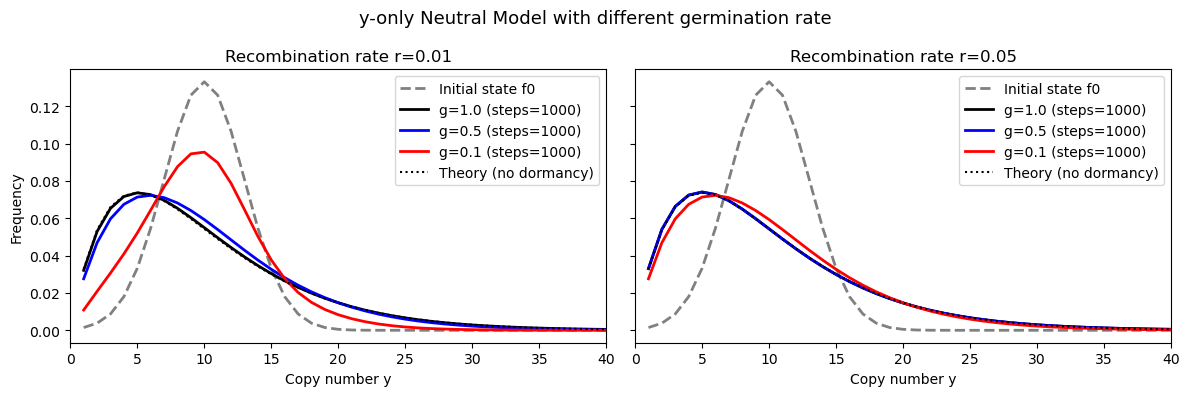

In [2]:
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T

# ---------- dormancy/germination update ----------
def f_post_neutral_germination(f_prior, r, g, T):
    """Deterministic neutral model with germination rate g."""
    f_prior = f_prior / f_prior.sum()
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)
    f_new = (1 - r) * f_prior + r * recomb
    f_post = g * f_new + (1 - g) * f_prior
    return f_post / f_post.sum()

def iterate_germination(f0, r, g, T, tol=1e-9, max_iter=1000):
    f = f0 / f0.sum()
    for i in range(max_iter):
        f_new = f_post_neutral_germination(f, r, g, T)
        if np.abs(f_new - f).sum() < tol:
            return f_new, i
        f = f_new
    return f, max_iter

# ---------- theoretical neutral stationary (only for g=1) ----------
def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    return p / p.sum()

# ---------- run simulation ----------
if __name__ == "__main__":
    n = 80  # maximum copy number considered
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution: gaussian around y=10
    f0 = np.exp(-((y - 10.0) ** 2) / (2 * 3.0 ** 2))
    f0 /= f0.sum()
    E0 = np.sum(y * f0)
    theory = stationary_theory_from_mean(E0, n)
    
    # Initial distribution: bimodal
    #f0 = np.zeros(n)
    #f0[5] = 0.4     # peak at y=6
    #f0[20] = 0.4    # peak at y=31
    #E0 = np.sum(y * f0)
    #theory = stationary_theory_from_mean(E0, n)

    recomb_rates = [0.01, 0.05]
    germ_rates = [1.0, 0.5, 0.1]   # 1=no dormancy, 0.5=avg 2-gen dormancy, 0.1=strong dormancy
    colors = ["black", "blue", "red"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, r in zip(axes, recomb_rates):
        # plot initial distribution
        ax.plot(y, f0, "gray", linestyle="--", lw=2, label="Initial state f0")
        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_germination(f0, r, g, T)
            ax.plot(y, f_eq, color=col, lw=2,
                    label=f"g={g} (steps={steps})")
        # only show theory for g=1
        ax.plot(y, theory, "k:", lw=1.5, label="Theory (no dormancy)")
        ax.set_title(f"Recombination rate r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()
    axes[0].set_ylabel("Frequency")
    fig.suptitle("y-only Neutral Model with different germination rate", fontsize=13)
    plt.tight_layout()
    plt.show()
